# 影像与临床二分类

按 **Shift+Enter** 从上到下逐单元运行。变量保留在当前内核中；如果修改上游参数，请重新运行其后的单元。

本教程使用固定合成数据，演示软件流程，不提供临床效能结论。需要完整仓库和对应原生安装包；源码环境为 `45140bf` 构建。

## 1. 环境与独立输出目录

确认后端为 Rust。后续每步都可以检查中间对象；示例数据生成辅助函数只负责小型输入构造。

In [1]:
from pathlib import Path
import sys, tempfile
from IPython.display import display, Image
# 从 Notebook 所在目录或仓库根目录启动均可。
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'examples/native/_shared.py').exists()), None)
if REPO is None:
    raise RuntimeError('请先下载完整仓库，并在仓库内启动 Jupyter。')
sys.path.insert(0, str(REPO/'examples/native'))
import ov_radiomics as rad
print(rad.backend_info())
# 每次完整运行使用新目录，避免覆盖已有结果。
output = Path(tempfile.mkdtemp(prefix='radiomics-02_image_clinical_binary-'))
root = output
print('输出目录:', output)

import ov_radiomics as rad
from _shared import output_arguments, image_cohort, provenance, save_patient_roc


{'metrics_backend': 'rust', 'rust_core_version': '0.1.0'}
输出目录: C:\Users\ADMINI~1.DES\AppData\Local\Temp\radiomics-02_image_clinical_binary-4635dyld


## 2. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [2]:
(extracted, identities, classes) = image_cohort(output)
features = ['original_firstorder_Mean', 'original_firstorder_Variance', 'original_firstorder_90Percentile']

## 3. 整理临床数据

临床表每位患者一行，随后按患者 ID 关联到病灶。many_to_one 校验用于防止重复连接。

In [3]:
clinical = identities.drop_duplicates('patient_id')[['patient_id', 'signal_b', 'noise_a', 'target', 'group']].copy()
if hasattr(clinical, 'head'):
    display(clinical.head())

,patient_id,signal_b,noise_a,target,group
0,binary-P000,0.427544,1.036511,negative,train
2,binary-P001,0.193706,-0.945580,positive,train
4,binary-P002,0.660924,-0.432494,negative,train
6,binary-P003,1.851856,2.170941,positive,train
8,binary-P004,0.041408,-0.940706,negative,train


## 4. 整理临床数据

临床表每位患者一行，随后按患者 ID 关联到病灶。many_to_one 校验用于防止重复连接。

In [4]:
clinical = clinical.rename(columns={'signal_b': 'clinical_a', 'noise_a': 'clinical_b'})
clinical['category'] = ['A' if i % 2 else 'B' for i in range(len(clinical))]
clinical.to_csv(output / 'clinical.csv', index=False)
if hasattr(clinical, 'head'):
    display(clinical.head())

,patient_id,clinical_a,clinical_b,target,group,category
0,binary-P000,0.427544,1.036511,negative,train,B
2,binary-P001,0.193706,-0.945580,positive,train,A
4,binary-P002,0.660924,-0.432494,negative,train,B
6,binary-P003,1.851856,2.170941,positive,train,A
8,binary-P004,0.041408,-0.940706,negative,train,B


## 5. 检查输入表

检查特征列、结局列和 train/test/external 队列。结局与 ID 不进入特征矩阵；测试集不参与填补、缩放或筛选拟合。

In [5]:
data = extracted.features.merge(identities[['ID', 'patient_id']], on='ID', validate='one_to_one').merge(clinical, on='patient_id', validate='many_to_one')
data.to_csv(output / 'study.csv', index=False)
if hasattr(data, 'head'):
    display(data.head())

,ID,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_Mean,original_firstorder_MeanAbsoluteDeviation,...,original_shape_basic_CentroidY_mm,original_shape_basic_CentroidZ_mm,original_shape_basic_Volume_mm3,original_shape_basic_VoxelCount,patient_id,clinical_a,clinical_b,target,group,category
0,binary-P000-L0,2.030408,2.881182,147.511965,1.650022,0.506413,2.303704,3.114132,2.455795,0.278527,...,-14.0,36.0,576.0,24.0,binary-P000,0.427544,1.036511,negative,train,B
1,binary-P000-L1,1.848073,2.697479,126.733063,1.489934,0.505599,2.303704,2.930055,2.272776,0.278080,...,-14.0,36.0,576.0,24.0,binary-P000,0.427544,1.036511,negative,train,B
2,binary-P001-L0,1.166663,2.011545,63.337509,1.594361,0.502906,2.303704,2.242881,1.589104,0.276598,...,-14.0,36.0,576.0,24.0,binary-P001,0.193706,-0.945580,positive,train,A
3,binary-P001-L1,1.445785,2.288122,86.367425,1.594361,0.501391,2.303704,2.518762,1.866954,0.275765,...,-14.0,36.0,576.0,24.0,binary-P001,0.193706,-0.945580,positive,train,A
4,binary-P002-L0,-0.580994,0.275661,3.367501,1.717091,0.509914,2.303704,0.510221,-0.152667,0.280453,...,-14.0,36.0,576.0,24.0,binary-P002,0.660924,-0.432494,negative,train,B


## 6. 配置特征筛选

这里关闭单因素和稀疏筛选以展示稳定的完整流程。真实研究应事先声明筛选方法和阈值；筛选在训练折内拟合。

In [6]:
selector = rad.FeatureSelector(backend='rust', univariate=None, lasso=False)

## 7. 拟合影像模型

指定原生 Rust 后端及患者层级。外层 CV 用于评价，内层 CV 用于选择配置；关注实际患者集合而不只是 fold 编号。

In [7]:
image = rad.train_models(data, 'target', features, backend='rust', classes=classes, positive_label=classes[1], selector=selector, cv=3, inner_cv=2, patient_id='patient_id')

## 8. 使用共享划分拟合临床模型

复用影像模型的 SplitPlan，确保两条分支的训练/验证患者完全一致。分类变量必须显式声明。

In [8]:
clinic = rad.train_models(data, 'target', ['clinical_a', 'clinical_b', 'category'], categorical=['category'], backend='rust', classes=classes, positive_label=classes[1], split_plan=image.split_plan, scale='standard')
image.save(output / 'image-model')
clinic.save(output / 'clinical-model')

## 9. 用 OOF 概率进行融合

融合拟合使用基础模型对未参与该折训练患者的预测。融合自身的训练表现属于表观表现，不能代替独立测试。

In [9]:
fusion = rad.fit_fusion(rad.fusion_data({'Image': image, 'Clinical': clinic}), backend='rust')
fusion.save(output / 'fusion.rad')
for (name, result) in [('image', image), ('clinical', clinic), ('fusion', fusion)]:
    rad.evaluate(result, backend='rust', prediction_unit='patient', ci_method=None).to_csv(output / (name + '-metrics.csv'), index=False)

## 10. 无标签外部预测

移除结局后进行预测，确认保存的填补、缩放、特征与类别顺序被复用。禁止重新拟合外部数据。

In [10]:
external = data.loc[data.group != 'train'].drop(columns='target')
before = image.predict(external)

## 11. 保存与重新加载

使用类型化 .rad 模型，检查加载后预测一致。重新运行保存单元前请改用新的输出目录。

In [11]:
restored = rad.load_model(output / 'image-model/model-000.rad')
assert before.to_dict() == restored.predict(external).to_dict()
before.dataframe.to_csv(output / 'unlabeled-predictions.csv', index=False)
save_patient_roc(image, data, output / 'heldout-patient-roc.png')
provenance(output, '02_image_clinical_binary', patients=data.patient_id.nunique(), samples=len(data), split_plan_sha256=image.split_plan.fingerprint, evaluation_unit='patient', fusion_training='verified base OOF; meta training predictions apparent')

## 12. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [12]:
print(rad.evaluate(image, ci_method=None).to_string(index=False))
print('Outputs:', output)

model      group   task prediction_unit  n prediction_type          status  positive_n  threshold  accuracy      auc  sensitivity  specificity      ppv      npv  precision   recall       f1    brier  log_loss_eps1e15  average_precision  pr_auc_trapezoidal  ci_low  ci_high
   LR external_A binary         patient  6        external prediction_only         NaN        NaN       NaN      NaN          NaN          NaN      NaN      NaN        NaN      NaN      NaN      NaN               NaN                NaN                 NaN     NaN      NaN
   LR       test binary         patient 12         holdout       evaluated         6.0        0.5  0.500000 0.722222     0.166667     0.833333 0.500000 0.500000   0.500000 0.166667 0.250000 0.230116          0.651746           0.740278            0.707110     NaN      NaN
   LR      train binary         patient 48        apparent       evaluated        24.0        0.5  0.604167 0.675347     0.541667     0.666667 0.619048 0.592593   0.619048 0.541667 

## 查看导出的图与文件

查看图表的坐标、单位和预测层级。输出目录保留完整结果；这里显示前两幅图。

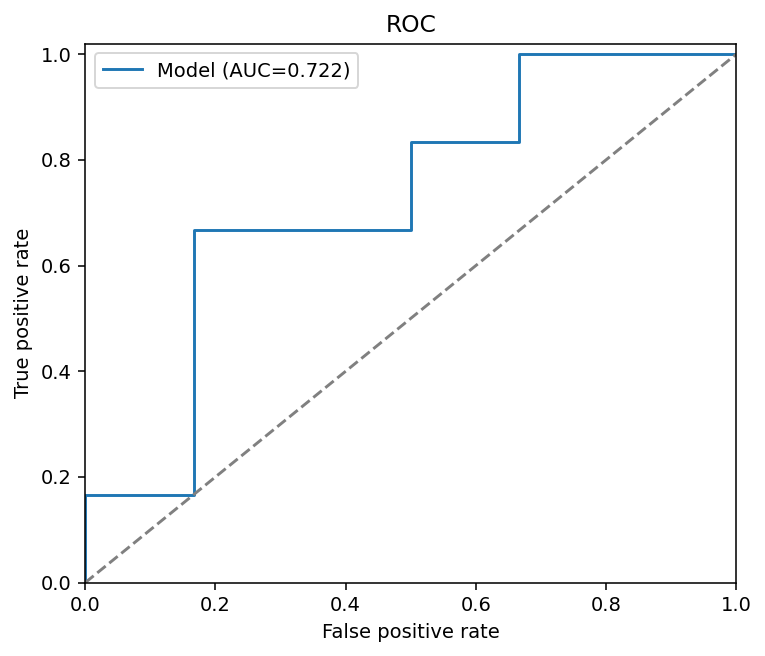

结果文件: ['clinical-metrics.csv', 'clinical-model', 'clinical.csv', 'cohort.csv', 'extract.json', 'extraction', 'fusion-metrics.csv', 'fusion.rad', 'heldout-patient-roc.png', 'image-metrics.csv', 'image-model', 'inputs', 'provenance.json', 'study.csv', 'unlabeled-predictions.csv']


In [13]:
for figure in sorted(output.glob('*.png'))[:2]:
    display(Image(filename=str(figure)))
print('结果文件:', [p.name for p in sorted(output.iterdir())])

## 换成自己的数据

保持示例的 ID、患者/切片层级与列角色约定，先替换数据读取步骤，再重新运行下游单元。先确认几何、单位、缺失状态和队列重叠；不要用测试集决定阈值或筛选参数。

重新运行全部单元会新建结果目录；只重跑保存单元可能因为文件已存在而报错，这是显式防覆盖行为。